In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN

from sklearn.decomposition              import PCA
import umap.umap_ as umap
import pacmap

from utils.Preprocessing                import PreProcessData
from utils.plotFigures                  import linePlot, lineAndScatterPlot, scatterPlot3D, scatterPlot2D
from clustering.clusteringTimeSeries    import ClusteringTimeSeries

# Preprocessing

In [2]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
df      = preData.splitTimeSeries()

scaler  = MinMaxScaler() 
preData.normalizeData(scaler);

## Split time series graph

In [3]:
linePlot(data   = df, 
         x      = 'tiempo', 
         y      = 'corriente(A)', 
         color  = 'trajectory')

# Clustering

In [4]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfManipulableVar = preData.scaledCrusher1[preData.manipulatedCr1]

clusteringModels    = {'umap':   DBSCAN(eps=2.2, min_samples=150, n_jobs=-1),
                       'pacmap': DBSCAN(eps=3, min_samples=200, n_jobs=-1)} 

dimReductionModels  = {'umap':   umap.UMAP(n_components=2),
                       'pacmap': pacmap.PaCMAP(n_components=2, save_tree=True)}

In [5]:
Clusters = ClusteringTimeSeries(data                = preData.crusher1, 
                                dataNormalized      = dfManipulableVar, 
                                clusteringModels    = clusteringModels, 
                                dimReductionModels  = dimReductionModels)

In [6]:
# Train dimensinality reduction models wiht a trajectory
Clusters.train(trainTrajectory='15')

In [7]:
# Clusters are calculated in embedding space
Clusters.getResults()

100%|██████████| 6/6 [01:11<00:00, 12.00s/it]


## Graphs of the results

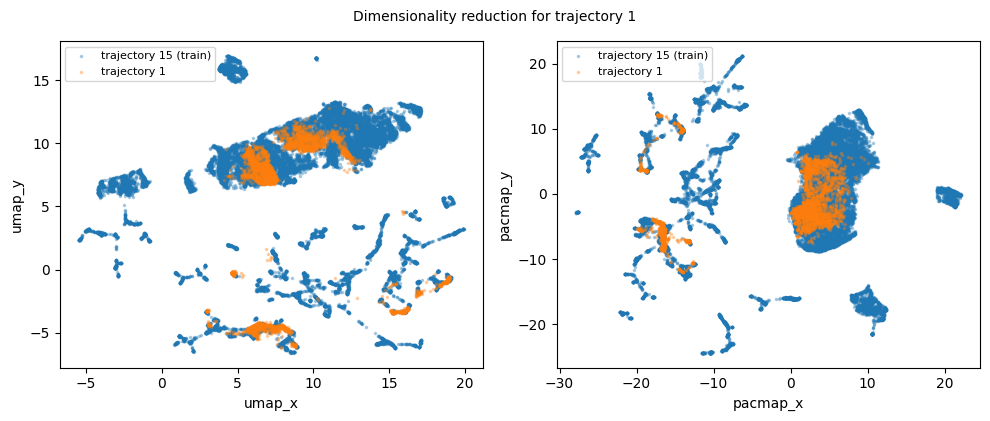

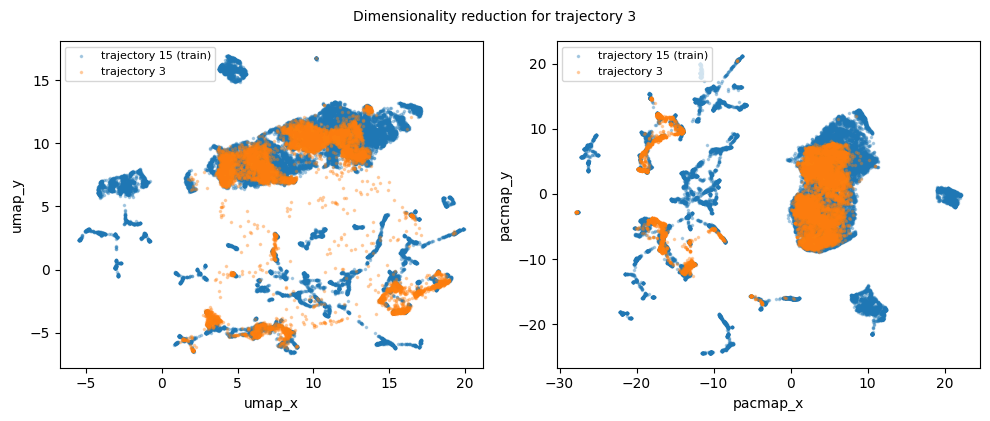

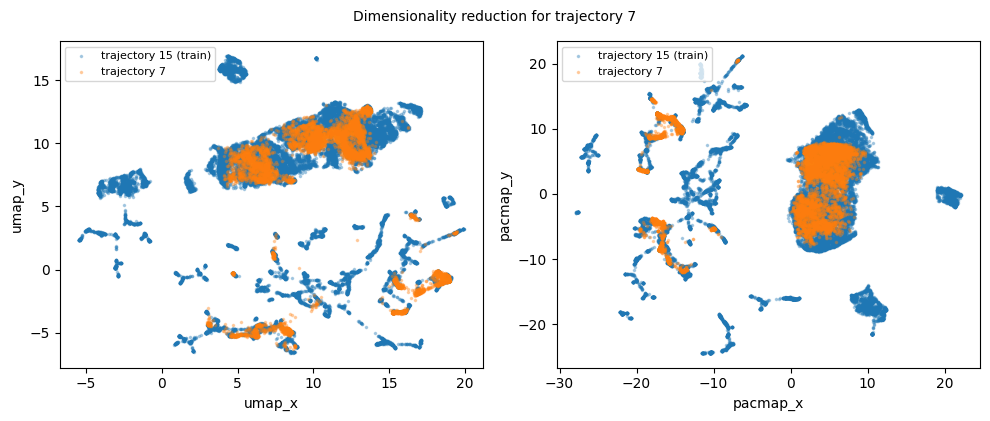

In [8]:
Clusters.plotEmbedding(nfigures=3)

### Comparison of clusters by dimensionality reduction algorithm

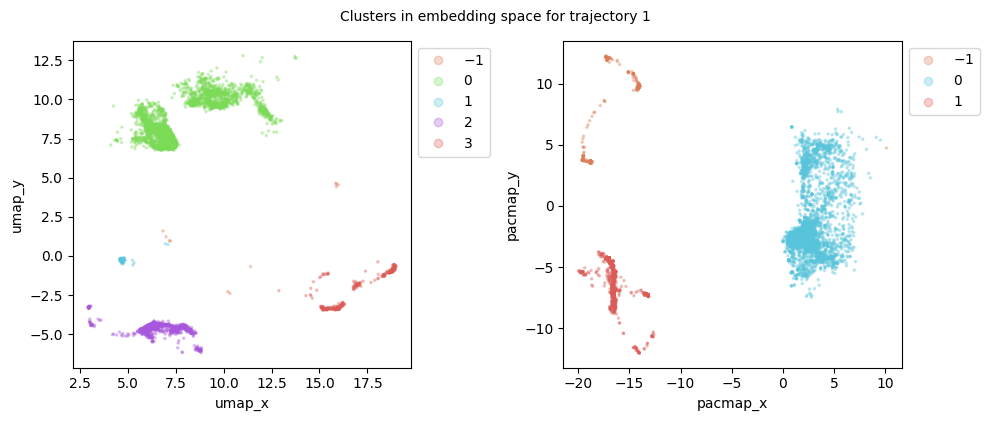

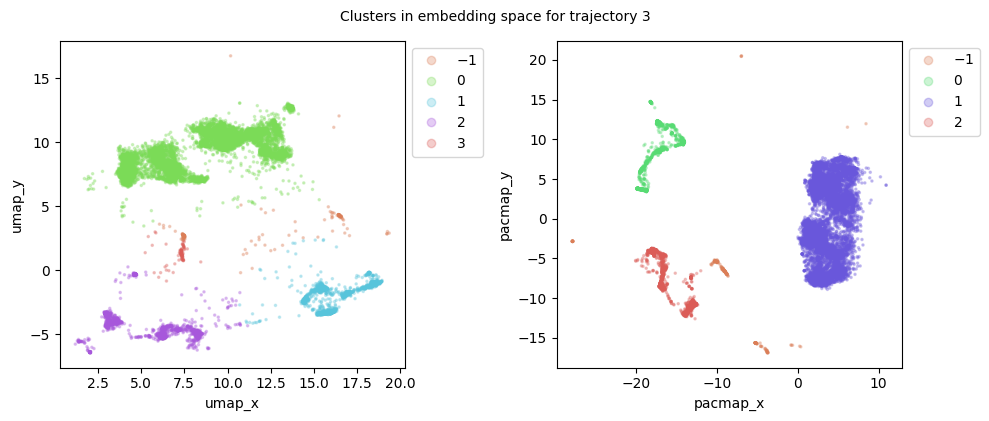

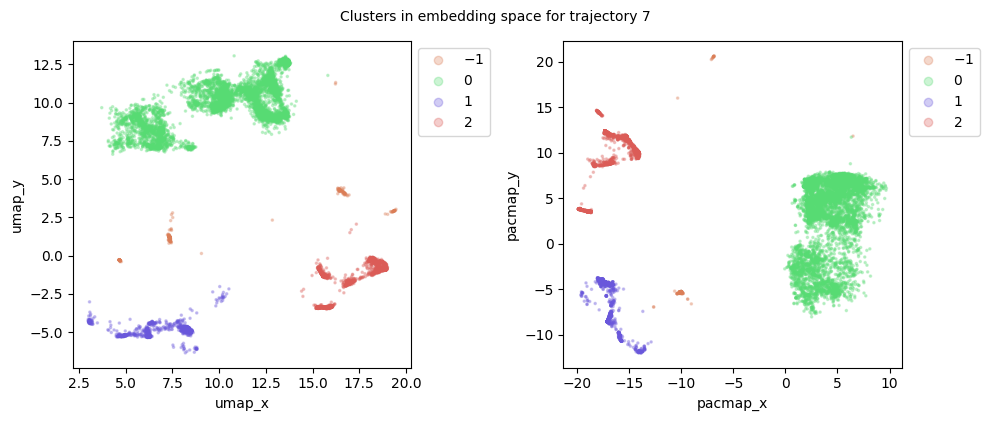

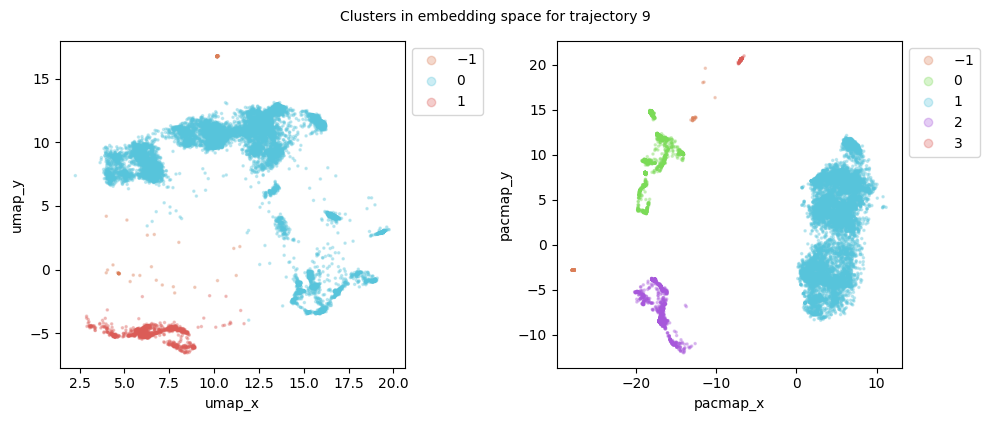

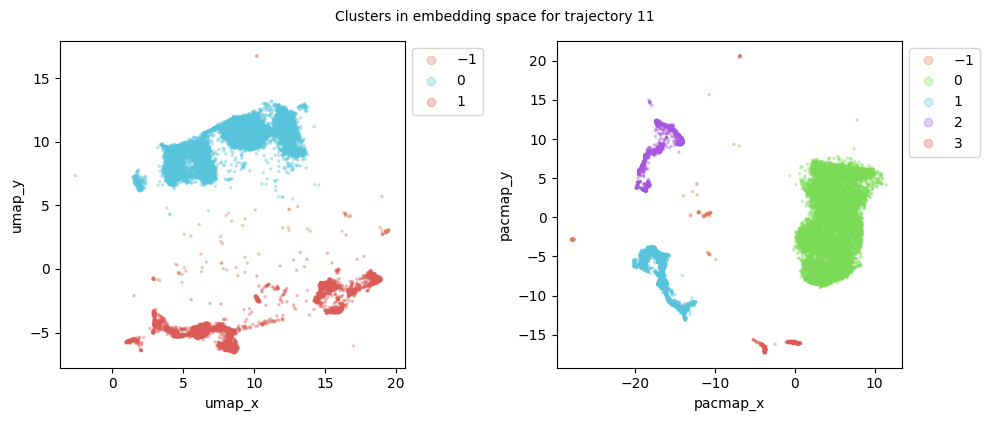

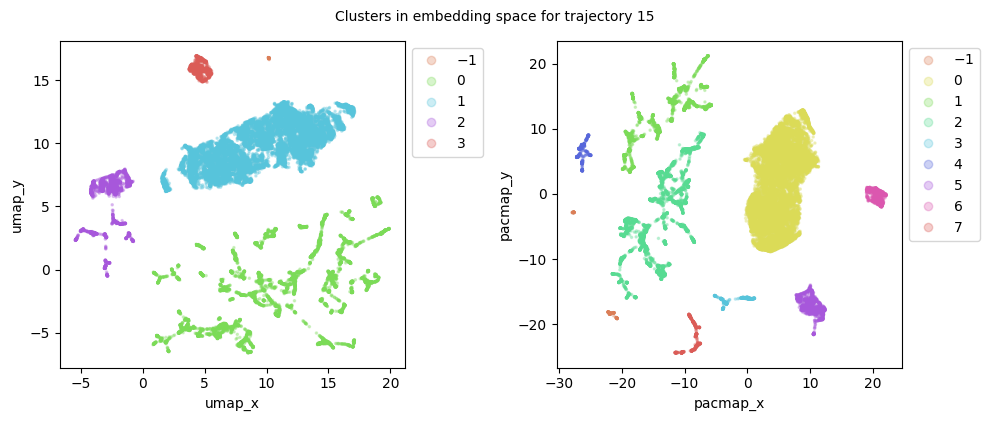

In [9]:
Clusters.plotResults(nfigures=6)

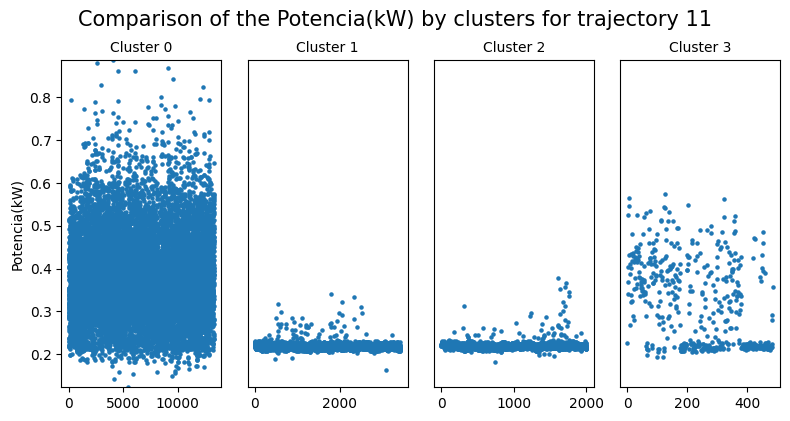

In [10]:
variable = dfManipulableVar.columns[2]
Clusters.plotVarByCluster(idxTrajectory = 4, 
                          variable      = variable, 
                          algorithm     = 'pacmap')

### Clusters in embedding space

In [11]:
Clusters.plotFigure('scatter2D', 
                    idxTrajectory   = 5, 
                    idxVariable     = 10, 
                    algorithm       = 'pacmap')

### Time series colored by clusters

In [12]:
Clusters.plotFigure('lineplot', 
                    idxTrajectory   = 3, 
                    idxVariable     = 0, 
                    algorithm       = 'pacmap')

# Clusters Comparison

In [13]:
dfSimilarClusters = Clusters.getSimilarClusters(algorithm = 'pacmap', 
                                                threshold = 5)

In [14]:
idxGroupCluster = 1
scatterPlot2D(data  = dfSimilarClusters[dfSimilarClusters['group']==idxGroupCluster], 
              x     = 'pacmap_x', 
              y     = 'pacmap_y',
              #z     = 'pacmap_z', 
              color = 'label',
              title = 'Similar clusters')

In [15]:
Clusters.getSimilarClusters(algorithm = 'umap', threshold = 5)
Clusters.unifyClusters(algorithm='umap')

Clusters.getSimilarClusters(algorithm = 'pacmap', threshold = 5)
Clusters.unifyClusters(algorithm='pacmap')

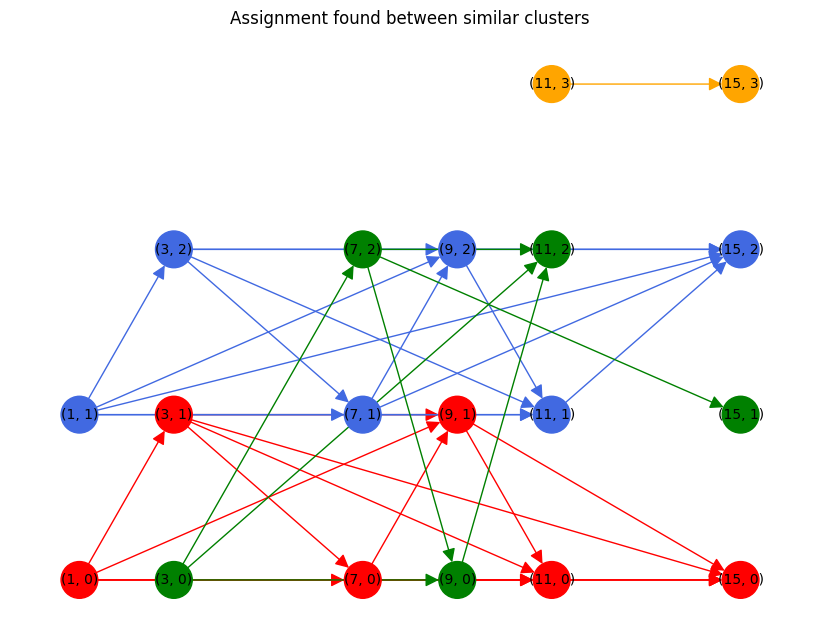

In [16]:
Clusters.plotGraph()

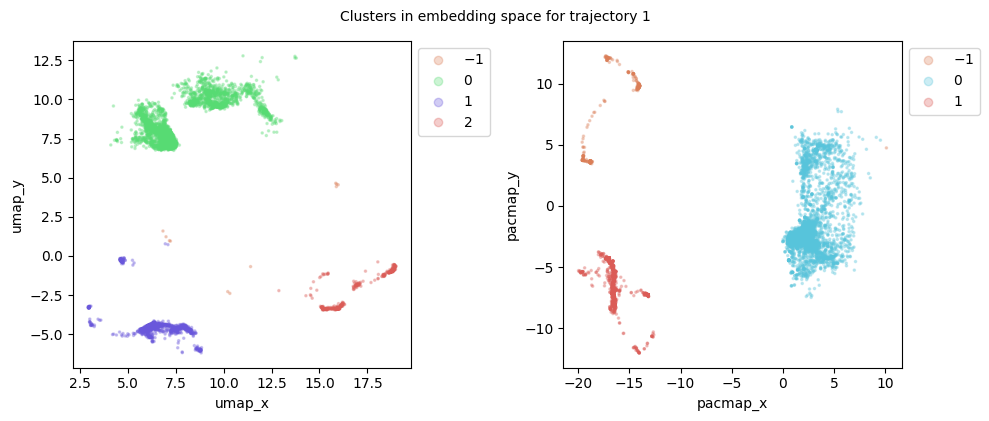

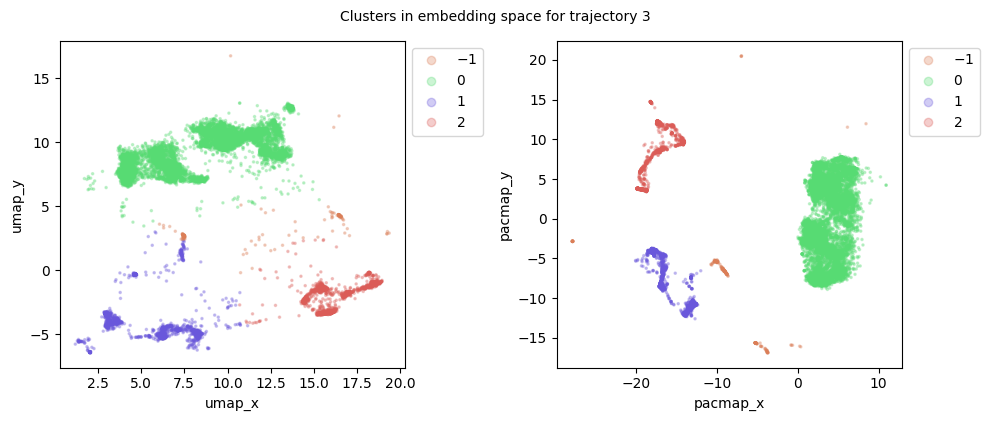

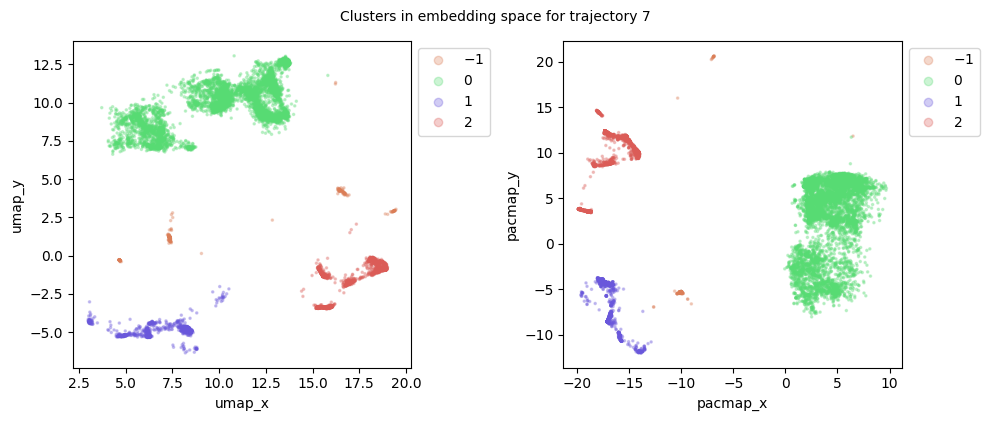

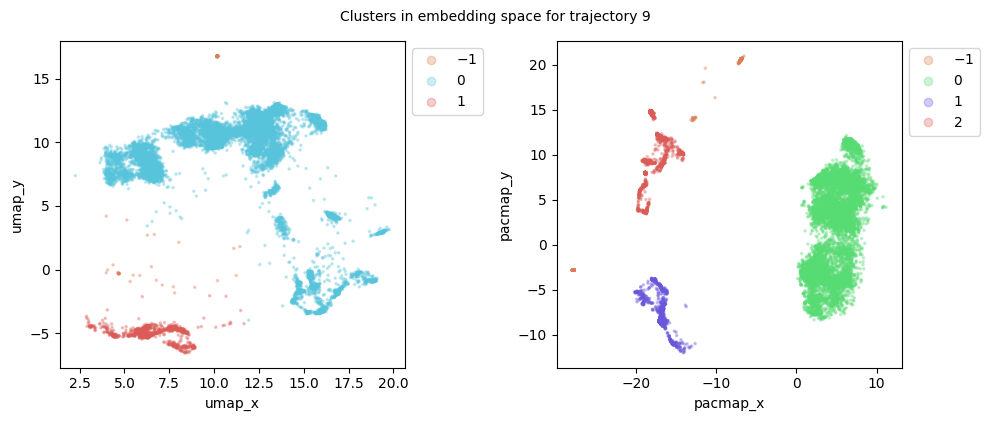

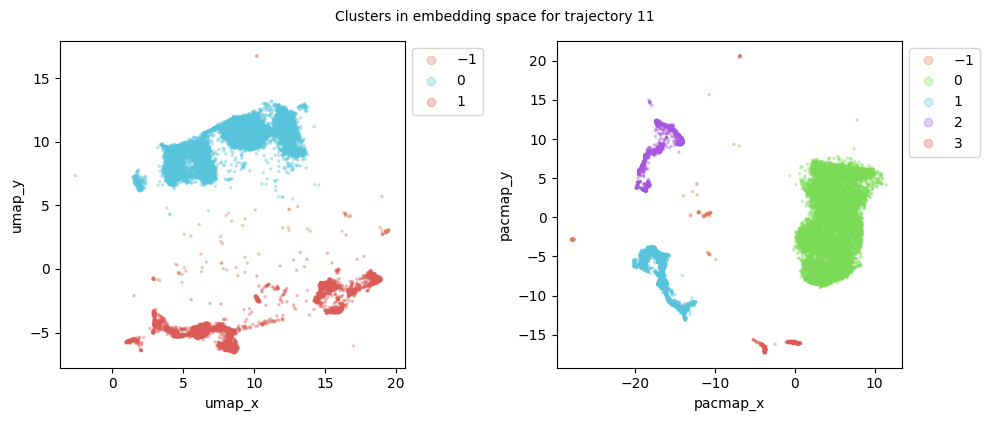

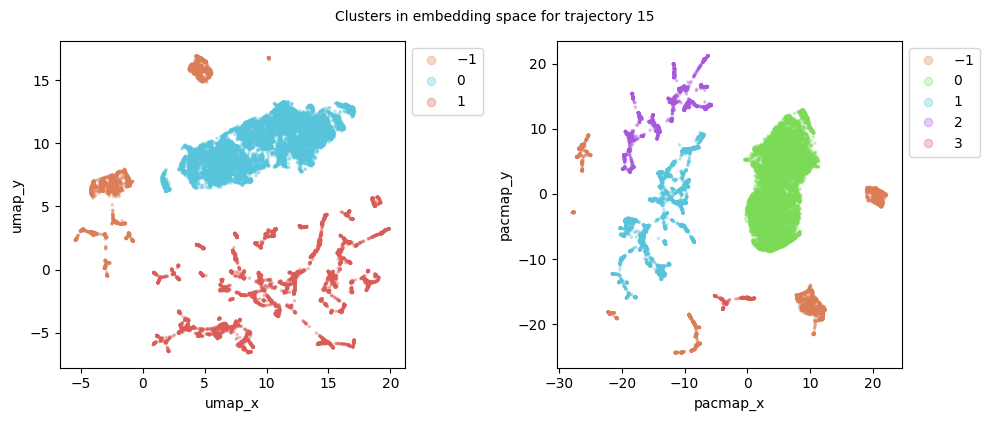

In [17]:
Clusters.plotResults(nfigures=6, 
                     label_color='real_cluster')

In [18]:
stop

NameError: name 'stop' is not defined

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors              import ListedColormap

nfigures = 6
cmap  = ListedColormap(sns.color_palette("hls", 64).as_hex()[10:])
label_color = 'real_cluster'
for i in range(nfigures):
    fig, axes  = plt.subplots(nrows   = 1, 
                            ncols   = 1, 
                            figsize = (4, 3))
    trajectory = Clusters.trajectories[i]
    data       = Clusters.getTrajectory(i)

    algorithm = Clusters.algorithms[1]
    scatterplot = axes.scatter(x      = data[f'{algorithm}_x'], 
                                    y      = data[f'{algorithm}_y'], 
                                    c      = data[f'{label_color}_{algorithm}'].astype(int), 
                                    cmap   = cmap,                
                                    marker = '.',
                                    alpha  = 0.3,
                                    s      = 10 )
    
    axes.set_xlabel(f'{algorithm}_x')
    axes.set_ylabel(f'{algorithm}_y')
    axes.legend(*scatterplot.legend_elements(), 
                    bbox_to_anchor = (1, 1),
                    loc            = 'upper left')
    axes.set_title(f'Clusters in embedding space for trajectory {trajectory}')

In [ ]:
stop

## Work in progress

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors              import ListedColormap

In [ ]:
dfResults = dfSimilarClusters.drop(columns=['pacmap_x', 'pacmap_y']).drop_duplicates().reset_index(drop=True)
dfResults['trajectory']=dfResults['trajectory'].astype('int')
dfResults

In [ ]:
similarity_tuples = [((group['trajectory'].iloc[0], group['cluster'].iloc[0]), 
           (group['trajectory'].iloc[1], group['cluster'].iloc[1]))
          for _, group in dfResults.groupby('group')]

In [ ]:
G = nx.DiGraph()

# Agregar nodos y aristas al grafo
for sim_tuple in similarity_tuples:
    source_node = sim_tuple[0]
    target_node = sim_tuple[1]
    G.add_edge(source_node, target_node)

# Encontrar componentes conectados
connected_components = list(nx.weakly_connected_components(G))


# Asignar colores a los nodos en función del componente conectado al que pertenecen
colors = ['red', 'royalblue', 'green', 'orange', 'purple', 'yellow'] 
node_colors = {}
edge_colors = {}
for i, component in enumerate(connected_components):
    print(f"Componente {i+1}: {component}")
    for node in component:
        node_colors[node] = colors[i % len(colors)]
    for edge in G.edges():
            if edge[0] in component and edge[1] in component:
                edge_colors[edge] = colors[i % len(colors)]

In [ ]:
for key, df in Clusters.clustersResults.items():
    # Inicializar una lista para almacenar el nombre de la componente conexa para cada fila
    component_names = []
    # Iterar sobre las filas del dataframe
    for index, row in df.iterrows():
        flag=False
        x = int(key) #row['x']  # Suponiendo que 'x' es el nombre de la columna que contiene los valores x
        y = int(row['cluster_pacmap'])  # Suponiendo que 'y' es el nombre de la columna que contiene los valores y
        # Buscar en qué componente conexa se encuentra la tupla (x, y)
        for i, component in enumerate(connected_components):

            if (x, y) in component:
                flag = True
                component_names.append(i) #f"Componente {i+1}")
                break  # Salir del bucle una vez que se ha encontrado la componente conexa
        if flag==False:
            component_names.append(-1) #f"No hay componente, cluster {y}")
    # Agregar la columna 'ComponenteConexa' al dataframe
    df['ComponenteConexa'] = component_names

In [ ]:
pos = {}
for node in G.nodes():
    pos[node] = (node[0], node[1])

# Visualizar el grafo
plt.figure(figsize=(8, 6))
nx.draw(G, pos, with_labels=True, node_size=700, 
        node_color=[node_colors[node] for node in G.nodes()], #node_color="skyblue", 
        edge_color=[edge_colors[edge] for edge in G.edges()], #edge_color='gray'
        font_size=10, arrowsize=20)


plt.xlabel('tr_i')
plt.ylabel('c_i')
plt.title("Grafo de Trayectos y Clusters")
plt.show()

In [ ]:
nfigures = 6

cmap  = ListedColormap(sns.color_palette("hls", 256).as_hex())
for i in range(nfigures):
    fig, axes  = plt.subplots(nrows   = 1, 
                            ncols   = 1, 
                            figsize = (5, 4))
    trajectory = Clusters.trajectories[i]
    data       = Clusters.getTrajectory(i)

    algorithm = Clusters.algorithms[1]
    scatterplot = axes.scatter(x      = data[f'{algorithm}_x'], 
                                    y      = data[f'{algorithm}_y'], 
                                    c      = data['ComponenteConexa'], 
                                    cmap   = cmap,                
                                    marker = '.',
                                    alpha  = 0.3,
                                    s      = 10 )
    
    axes.set_xlabel(f'{algorithm}_x')
    axes.set_ylabel(f'{algorithm}_y')
    axes.legend(*scatterplot.legend_elements(), 
                    bbox_to_anchor = (1, 1),
                    loc            = 'upper left')
    axes.set_title(f'Clusters in embedding space for trajectory {trajectory}')